# Explore the pipeline
All the code lives in the `analog_engine` package; this notebook only runs steps and looks at results.
From a terminal the same thing is `python -m analog_engine [download planets base score frontend]`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "analog_engine").is_dir():  # works from AnalogEngine/, notebooks/ or scripts/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from analog_engine import filters, likeness, pipeline, plots, scoring, validation
from analog_engine.config import PROCESSED, RAW

## Run steps (comment out what is already up to date)

In [2]:
pipeline.download()                  # raw data, skips files on disk
pipeline.run_planets()               # Moon / Mars terrain tables
pipeline.run_base()                  # Earth table + filters + likeness -> cells.parquet
pipeline.run_score()                 # applications -> cells_scored.parquet
pipeline.run_frontend()              # frontend_cells.json

↓ downloading wc2.1_10m_bio.zip ...
✓ unzipped WorldClim


/home/mmacura/miniforge3/envs/spaceapps/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Enter your Earthdata Login username:  nasa.routing763@passmail.net
Enter your Earthdata password:  ········


QUEUEING TASKS | : 100%|████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 753.83it/s]
PROCESSING TASKS | : 100%|███████████████████████████████████████████████████████████████| 1/1 [00:16<00:00, 16.84s/it]
COLLECTING RESULTS | : 100%|██████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 10837.99it/s]


✓ downloaded MCD12C1.A2022001.061.2023244164746.hdf
picked: GEDI_HighQuality_Shots_Rasters.gediv002_agbd-a0-qf_vf_20190417_20230316_12000m.tif


QUEUEING TASKS | : 100%|████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 485.56it/s]
PROCESSING TASKS | : 100%|███████████████████████████████████████████████████████████████| 1/1 [00:02<00:00,  2.36s/it]
COLLECTING RESULTS | : 100%|██████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 12018.06it/s]


↓ downloading ETOPO_2022_v1_15s_N00E000_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00E015_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00E030_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00E045_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00E060_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00E075_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00E090_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00E105_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00E120_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00E135_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00E150_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00E165_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00W015_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00W030_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00W045_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00W060_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00W075_surface.tif ...
↓ downloading ETOPO_2022_v1_15s_N00W090_surface.

/home/mmacura/miniforge3/envs/spaceapps/lib/python3.12/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


  + water_pct, forest_pct, urban_pct, snow_pct, barren_pct
→ barren ...
  + barren
→ gedi_agbd ...
  + biomass
→ biomass_gapfill ...
  + biomass
→ etopo2022 ...
  + elev_min, elev_max, elev_mean, elev_p05, elev_p95, elev_range, relief_p90, hyps, slope_mean, slope_p50, slope_p90, rough_p10, rough_p50
→ elevation ...
  + elevation, elev_p
→ polar ...
  + polar
        step  cells
       start  95447
after forest  77604
 after urban  75125
 after water  62621
 after slope  58272
 after rough  57735
                 name   lat    lon  forest_pct  urban_pct  water_pct  biomass  slope_p90  rough_p10  passes_all         excluded_by
       Atacama Desert -24.5  -69.2         0.0        0.0        0.0      4.6        9.1        8.9        True                    
Antarctic Dry Valleys -77.5  162.0         0.0        0.0        0.0      0.0       26.6        7.1       False               slope
      Haughton Crater  75.4  -89.7         0.0        0.0        0.0      0.0        4.1        3.6    

PosixPath('/home/mmacura/NasaSpaceProject/AnalogEngine/public/data/frontend_cells.json')

## Screening

,step,cells
0,start,95447
1,after forest,77604
2,after urban,75125
3,after water,62621
4,after slope,58272
5,after rough,57735


,name,lat,lon,forest_pct,urban_pct,water_pct,biomass,slope_p90,rough_p10,passes_all,excluded_by
0,Atacama Desert,-24.5,-69.2,0.0,0.0,0.0,4.6,9.1,8.9,True,
1,Antarctic Dry Valleys,-77.5,162.0,0.0,0.0,0.0,0.0,26.6,7.1,False,slope
2,Haughton Crater,75.4,-89.7,0.0,0.0,0.0,0.0,4.1,3.6,True,
3,Mauna Kea,19.8,-155.5,35.0,0.2,13.5,NaN,8.1,9.4,False,forest
4,Black Point Lava Flow,35.7,-111.4,0.0,0.0,0.0,6.2,3.0,2.7,True,
5,Rio Tinto,37.7,-6.6,5.0,0.7,0.0,48.5,6.3,10.1,True,
6,Teide,28.3,-16.6,2.8,1.6,53.0,NaN,16.4,19.1,False,"water, slope, rough"


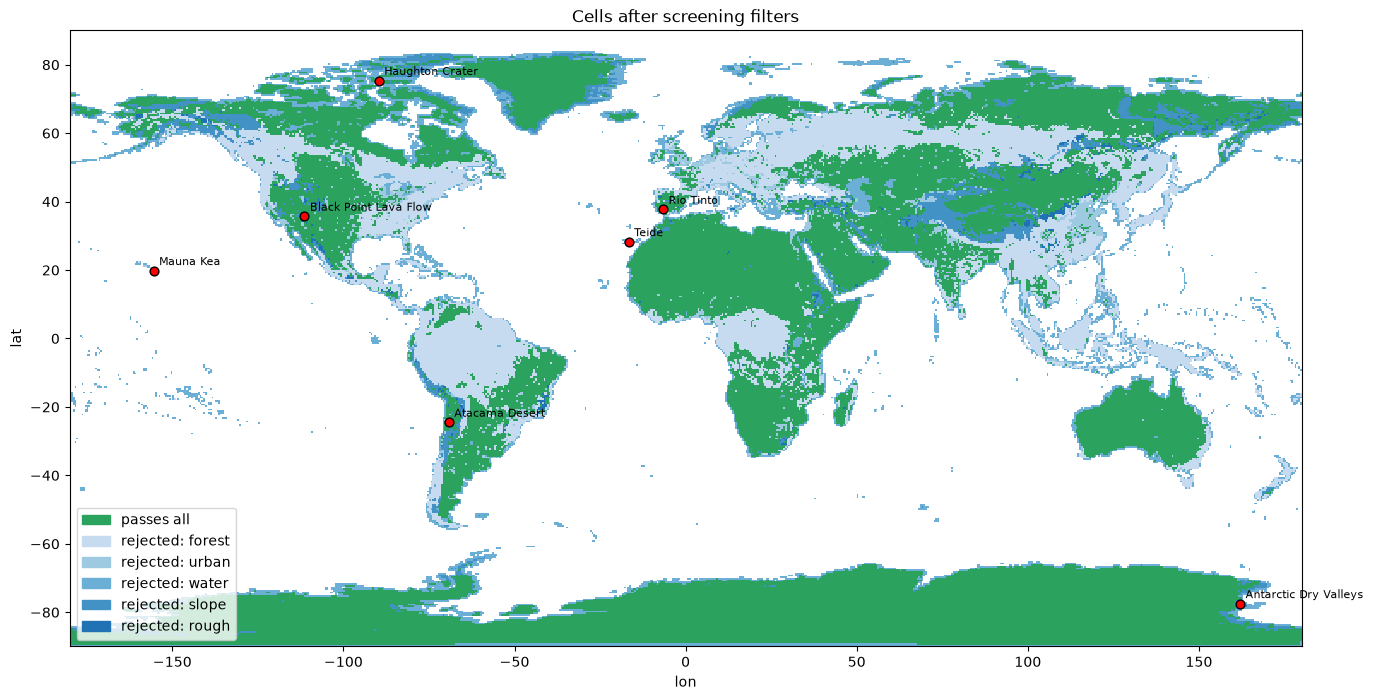

In [3]:
cells = pd.read_parquet(PROCESSED / "cells.parquet")
display(filters.funnel(cells))
display(validation.check_screening(cells))
plots.screening_map(cells, validation.screening_sites()); plt.show()

## Moon / Mars likeness

In [4]:
matches = pd.read_parquet(PROCESSED / "site_matches.parquet")
display(matches[matches["rank"] == 1].drop(columns=["rank", "site_cell_id"]
        + [c for c in matches if c.startswith("dz_")]).round(2))
for body in likeness.BODIES:
    print(f"Most {body}-like Earth cells:")
    display(cells.nlargest(5, f"{body}_like")[["cell_id", "lat", "lon", *likeness.TOPO_FEATURES, f"{body}_like"]].round(2))

,body,site,earth_cell_id,earth_lat,earth_lon,site_polar,earth_polar,distance,similarity,site_slope_p50,earth_slope_p50,site_slope_p90,earth_slope_p90,site_rough_p50,earth_rough_p50,site_relief_p90,earth_relief_p90,site_hyps,earth_hyps
0,moon,Shackleton rim (south pole),28382,70.25,-28.75,True,False,0.49,0.62,11.67,11.69,29.27,28.49,47.73,56.91,3952.66,2237.62,0.61,0.58
10,moon,Malapert massif,147807,-12.75,-76.25,True,False,0.56,0.57,14.83,12.74,24.09,23.03,74.10,98.43,7444.87,4008.94,0.41,0.39
20,moon,"Apollo 11, Mare Tranquillitatis",166710,-25.75,15.25,False,False,0.10,0.90,0.73,0.74,1.53,1.62,5.29,5.83,515.89,482.82,0.49,0.50
30,moon,"Apollo 15, Hadley Rille",72498,39.75,69.25,False,False,0.19,0.83,6.71,6.34,22.46,24.77,46.90,44.38,3494.40,2872.86,0.31,0.32
40,moon,"Apollo 17, Taurus-Littrow",78226,35.75,53.25,False,False,0.10,0.90,8.19,7.97,21.04,19.37,56.25,59.96,1879.81,1844.48,0.42,0.42
50,moon,Marius Hills pit,189585,-41.75,-67.25,False,False,0.20,0.82,0.89,0.97,3.25,4.11,6.30,6.14,599.50,632.57,0.50,0.50
60,moon,"Chang'e 4, Von Karman",45406,58.25,-156.75,False,False,0.10,0.91,0.36,0.44,1.44,1.33,2.82,2.83,101.91,102.93,0.21,0.21
70,mars,Jezero (Perseverance),179502,-34.75,-68.75,False,False,0.21,0.81,1.54,1.41,6.70,6.01,10.00,9.51,806.00,662.70,0.52,0.53
80,mars,Gale (Curiosity),65350,44.75,95.25,False,False,0.22,0.80,3.18,3.55,11.22,12.15,20.50,23.05,2307.00,1901.49,0.45,0.46
90,mars,Elysium Planitia (InSight),81078,33.75,39.25,False,False,0.07,0.93,0.21,0.19,0.51,0.52,1.38,1.29,66.00,62.48,0.59,0.59


Most moon-like Earth cells:


,cell_id,lat,lon,slope_p50,slope_p90,rough_p50,relief_p90,hyps,moon_like
37088,76688,36.75,4.25,7.89,15.29,53.50,2263.33,0.59,0.88
65113,163664,-23.75,-67.75,5.48,14.21,36.93,2153.47,0.51,0.87
35165,72554,39.75,97.25,6.50,15.94,47.43,2137.97,0.42,0.87
31544,65665,44.25,-107.25,6.02,12.85,38.21,1871.47,0.49,0.87
32554,67480,43.25,80.25,6.66,16.20,48.15,1913.67,0.50,0.87


Most mars-like Earth cells:


,cell_id,lat,lon,slope_p50,slope_p90,rough_p50,relief_p90,hyps,mars_like
13777,37610,63.75,-94.75,0.32,0.80,1.68,96.95,0.45,0.93
7332,29673,69.25,-103.25,0.33,0.88,1.48,54.46,0.30,0.93
83160,246562,-81.25,-18.75,0.35,0.81,1.55,93.72,0.43,0.93
11560,34972,65.75,26.25,0.29,0.71,1.43,69.97,0.45,0.93
14657,38769,63.25,124.75,0.31,0.74,1.63,68.19,0.39,0.92


## Applications

In [5]:
scored = pd.read_parquet(PROCESSED / "cells_scored.parquet")
apps = [a.name for a in scoring.APPLICATIONS]
for app in scoring.APPLICATIONS:
    print(app.name)
    display(scoring.top(scored, app))
display(validation.check_applications(scored, apps))

cave


,cell_id,lat,lon,dist_basalt_volc_km,precip_p,temp_p,barren,score_cave_moon,score_cave_mars,label_cave
45393,95411,23.75,5.75,20.58,0.15,0.77,1.00,1.00,0.63,moon
45684,96131,23.25,5.75,12.08,0.20,0.73,1.00,1.00,0.65,moon
46875,99032,21.25,16.25,12.16,0.20,0.80,1.00,1.00,0.61,moon
65296,164382,-24.25,-68.75,17.94,0.08,0.64,1.00,1.00,0.70,moon
48480,103385,18.25,32.75,8.90,0.11,0.99,1.00,1.00,0.51,moon
47670,101197,19.75,18.75,23.68,0.15,0.80,1.00,1.00,0.61,moon
65659,165823,-25.25,-68.25,19.19,0.16,0.57,1.00,1.00,0.74,moon
44567,93315,25.25,37.75,8.90,0.19,0.83,1.00,1.00,0.59,moon
40067,83235,32.25,37.75,18.21,0.20,0.74,0.98,0.99,0.65,moon
46041,96922,22.75,41.25,14.44,0.23,0.98,1.00,0.99,0.51,moon


rover


,cell_id,lat,lon,moon_like_p,mars_like_p,precip_p,temp_p,barren,slope_p90,score_rover_moon,score_rover_mars,label_rover
31809,66073,44.25,96.75,0.91,0.94,0.15,0.58,1.0,1.63,1.0,0.93,moon
32975,68245,42.75,102.75,0.93,0.97,0.19,0.60,1.0,0.71,1.0,0.91,moon
33329,68946,42.25,93.25,0.95,0.95,0.11,0.65,1.0,2.07,1.0,0.90,moon
33346,68963,42.25,101.75,0.96,0.97,0.14,0.62,1.0,1.59,1.0,0.91,moon
33347,68964,42.25,102.25,0.97,0.98,0.15,0.62,1.0,1.33,1.0,0.91,moon
33687,69661,41.75,90.75,0.91,0.76,0.14,0.62,1.0,1.61,1.0,0.88,moon
33690,69664,41.75,92.25,0.92,0.86,0.13,0.63,1.0,1.42,1.0,0.91,moon
33693,69667,41.75,93.75,0.94,0.71,0.14,0.63,1.0,1.27,1.0,0.85,moon
33694,69668,41.75,94.25,0.93,0.88,0.15,0.62,1.0,1.52,1.0,0.91,moon
33702,69676,41.75,98.25,0.95,0.81,0.18,0.59,1.0,1.57,1.0,0.90,moon


spacewalk


,cell_id,lat,lon,temp_range_p,temp_p,elev_p,precip_p,barren,score_spacewalk_moon,score_spacewalk_mars,label_spacewalk
30612,63916,45.75,98.25,0.91,0.52,0.75,0.21,0.99,0.98,0.91,moon
36877,76127,37.25,83.75,0.88,0.64,0.75,0.11,1.00,0.97,0.90,moon
38557,79721,34.75,80.75,0.74,0.40,1.00,0.14,0.98,0.90,0.97,mars
32598,67524,43.25,102.25,0.90,0.58,0.74,0.22,1.00,0.97,0.89,moon
38558,79722,34.75,81.25,0.73,0.40,1.00,0.14,0.97,0.89,0.97,mars
31017,64631,45.25,95.75,0.87,0.53,0.77,0.21,0.99,0.97,0.91,moon
32597,67523,43.25,101.75,0.88,0.57,0.75,0.22,1.00,0.97,0.90,moon
31419,65351,44.75,95.75,0.86,0.54,0.77,0.21,0.99,0.97,0.91,moon
36532,75410,37.75,85.25,0.88,0.64,0.74,0.13,1.00,0.97,0.90,moon
31012,64626,45.25,93.25,0.89,0.53,0.75,0.23,1.00,0.97,0.90,moon


craters


,cell_id,lat,lon,dist_crater_km,precip_p,temp_p,barren,score_craters_moon,score_craters_mars,label_craters
42959,89650,27.75,5.25,21.33,0.10,0.82,1.0,1.0,0.84,moon
44543,93288,25.25,24.25,9.76,0.02,0.81,1.0,1.0,0.84,moon
45069,94660,24.25,-9.75,10.14,0.08,0.90,1.0,1.0,0.81,moon
45942,96819,22.75,-10.25,24.69,0.09,0.96,1.0,1.0,0.79,moon
47925,101918,19.25,19.25,16.68,0.05,0.94,1.0,1.0,0.80,moon
48468,103373,18.25,26.75,18.59,0.12,0.86,1.0,1.0,0.83,moon
47347,100414,20.25,-12.75,7.89,0.18,0.96,1.0,1.0,0.78,moon
48938,104803,17.25,21.75,18.75,0.18,0.92,1.0,1.0,0.80,moon
65112,163663,-23.75,-68.25,19.77,0.12,0.67,1.0,1.0,0.90,moon
43889,91808,26.25,4.25,23.14,0.08,0.90,1.0,1.0,0.81,moon


Known sites labelled for their own application: 15 of 18


,used_for,name,barren,precip_p,temp_p,slope_p90,label_cave,label_rover,label_spacewalk,label_craters,excluded_by,hit
0,cave,"Craters of the Moon, Idaho",0.04,0.48,0.60,6.77,moon,,,,,True
1,cave,"Lava Beds, California",0.01,0.60,0.61,8.19,moon,,,,,True
2,cave,"Mauna Loa (HI-SEAS), Hawaii",0.12,0.95,0.71,8.14,,,,,forest,False
3,cave,"Cueva de los Verdes, Lanzarote",0.02,0.29,0.75,10.20,moon,,,,water,True
4,cave,"Undara, Australia",0.00,0.77,0.78,1.55,moon,,,,,True
5,cave,"Raufarhólshellir, Iceland",0.03,0.85,0.55,11.77,both,,,,,True
6,rover,"Atacama (Yungay), Chile",1.00,0.01,0.71,5.73,,moon,mars,,,True
7,rover,"MDRS, Utah",0.36,0.33,0.66,9.05,,,both,,,False
8,rover,"Ramon Crater (D-MARS), Negev",0.99,0.30,0.73,5.32,,moon,mars,,,True
9,rover,"Erfoud (Ibn Battuta), Morocco",0.95,0.22,0.78,2.51,,moon,both,,,True


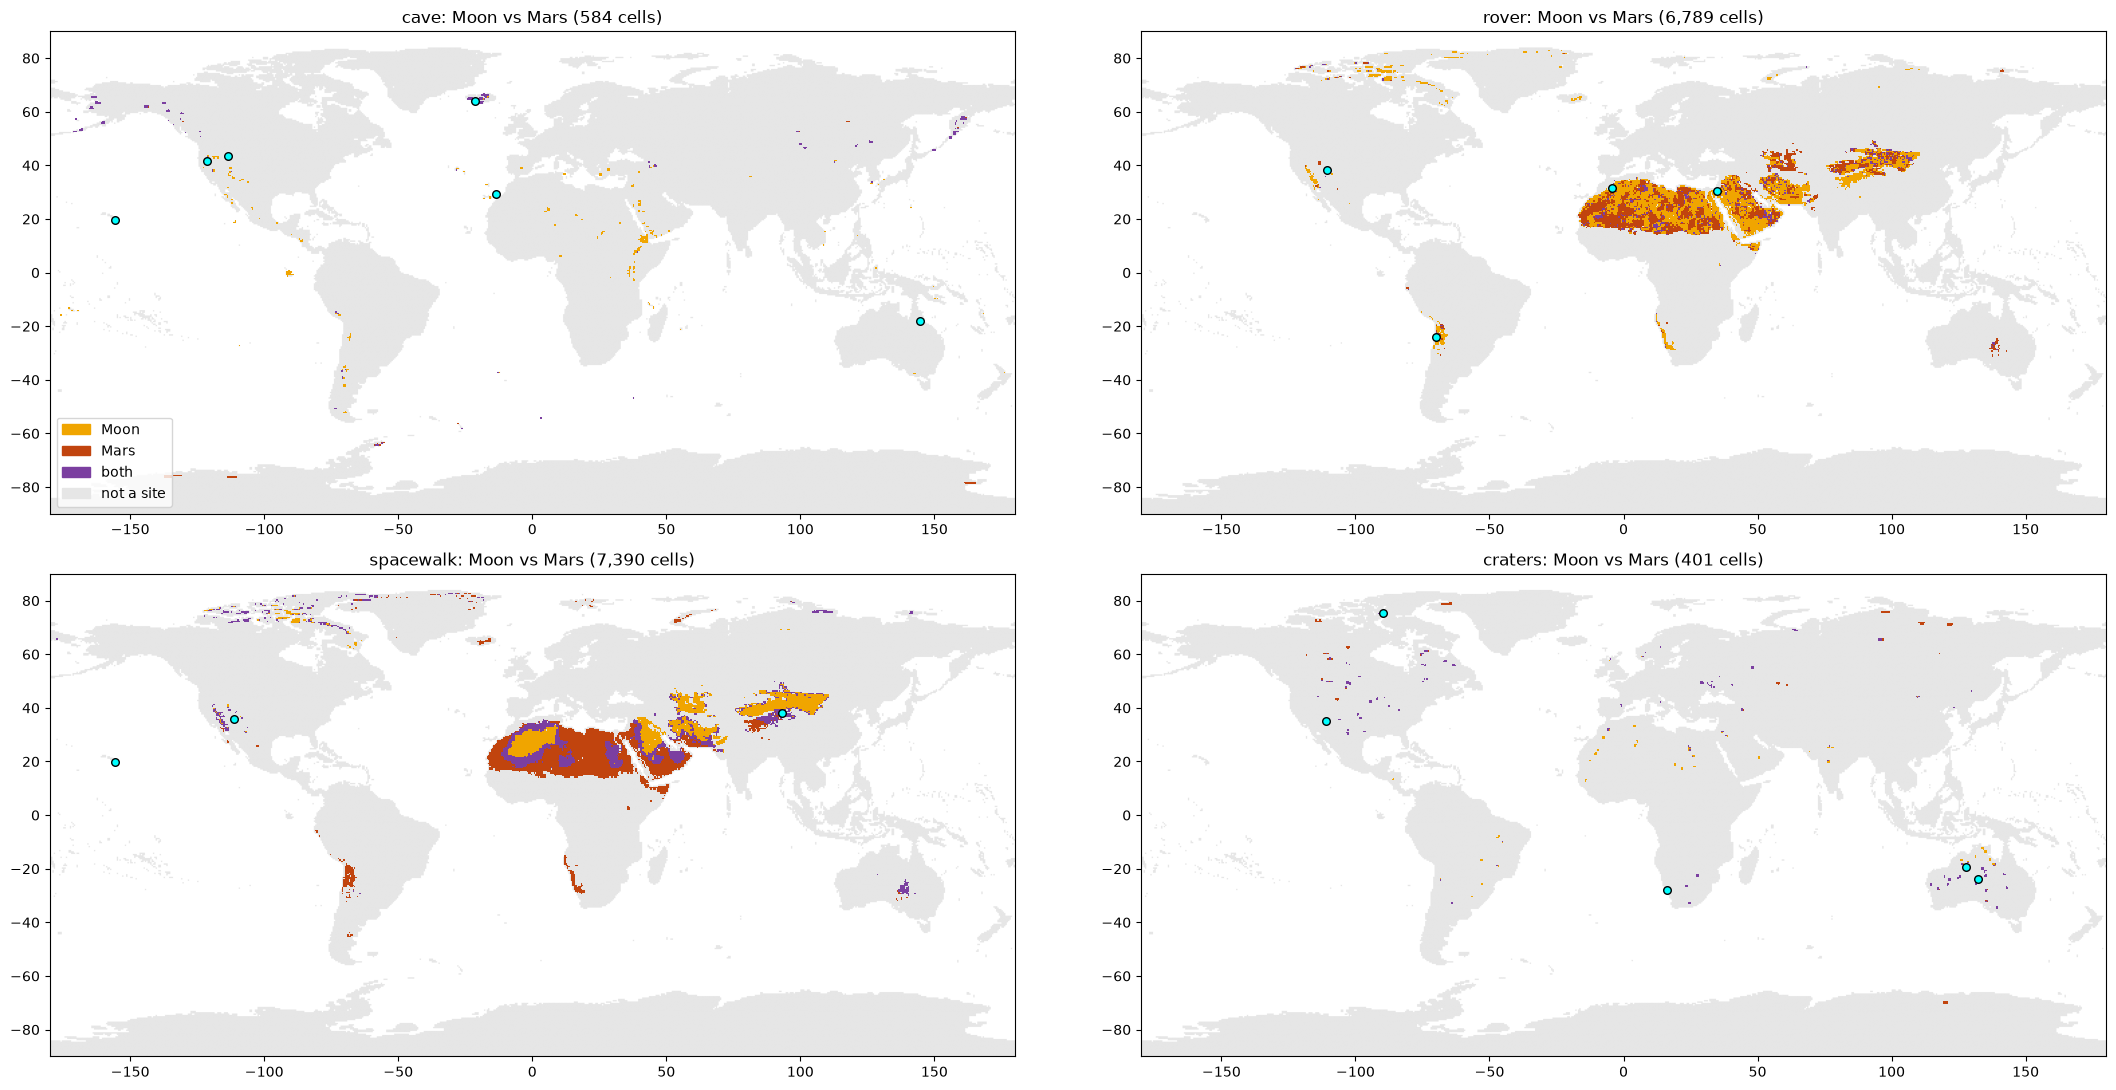

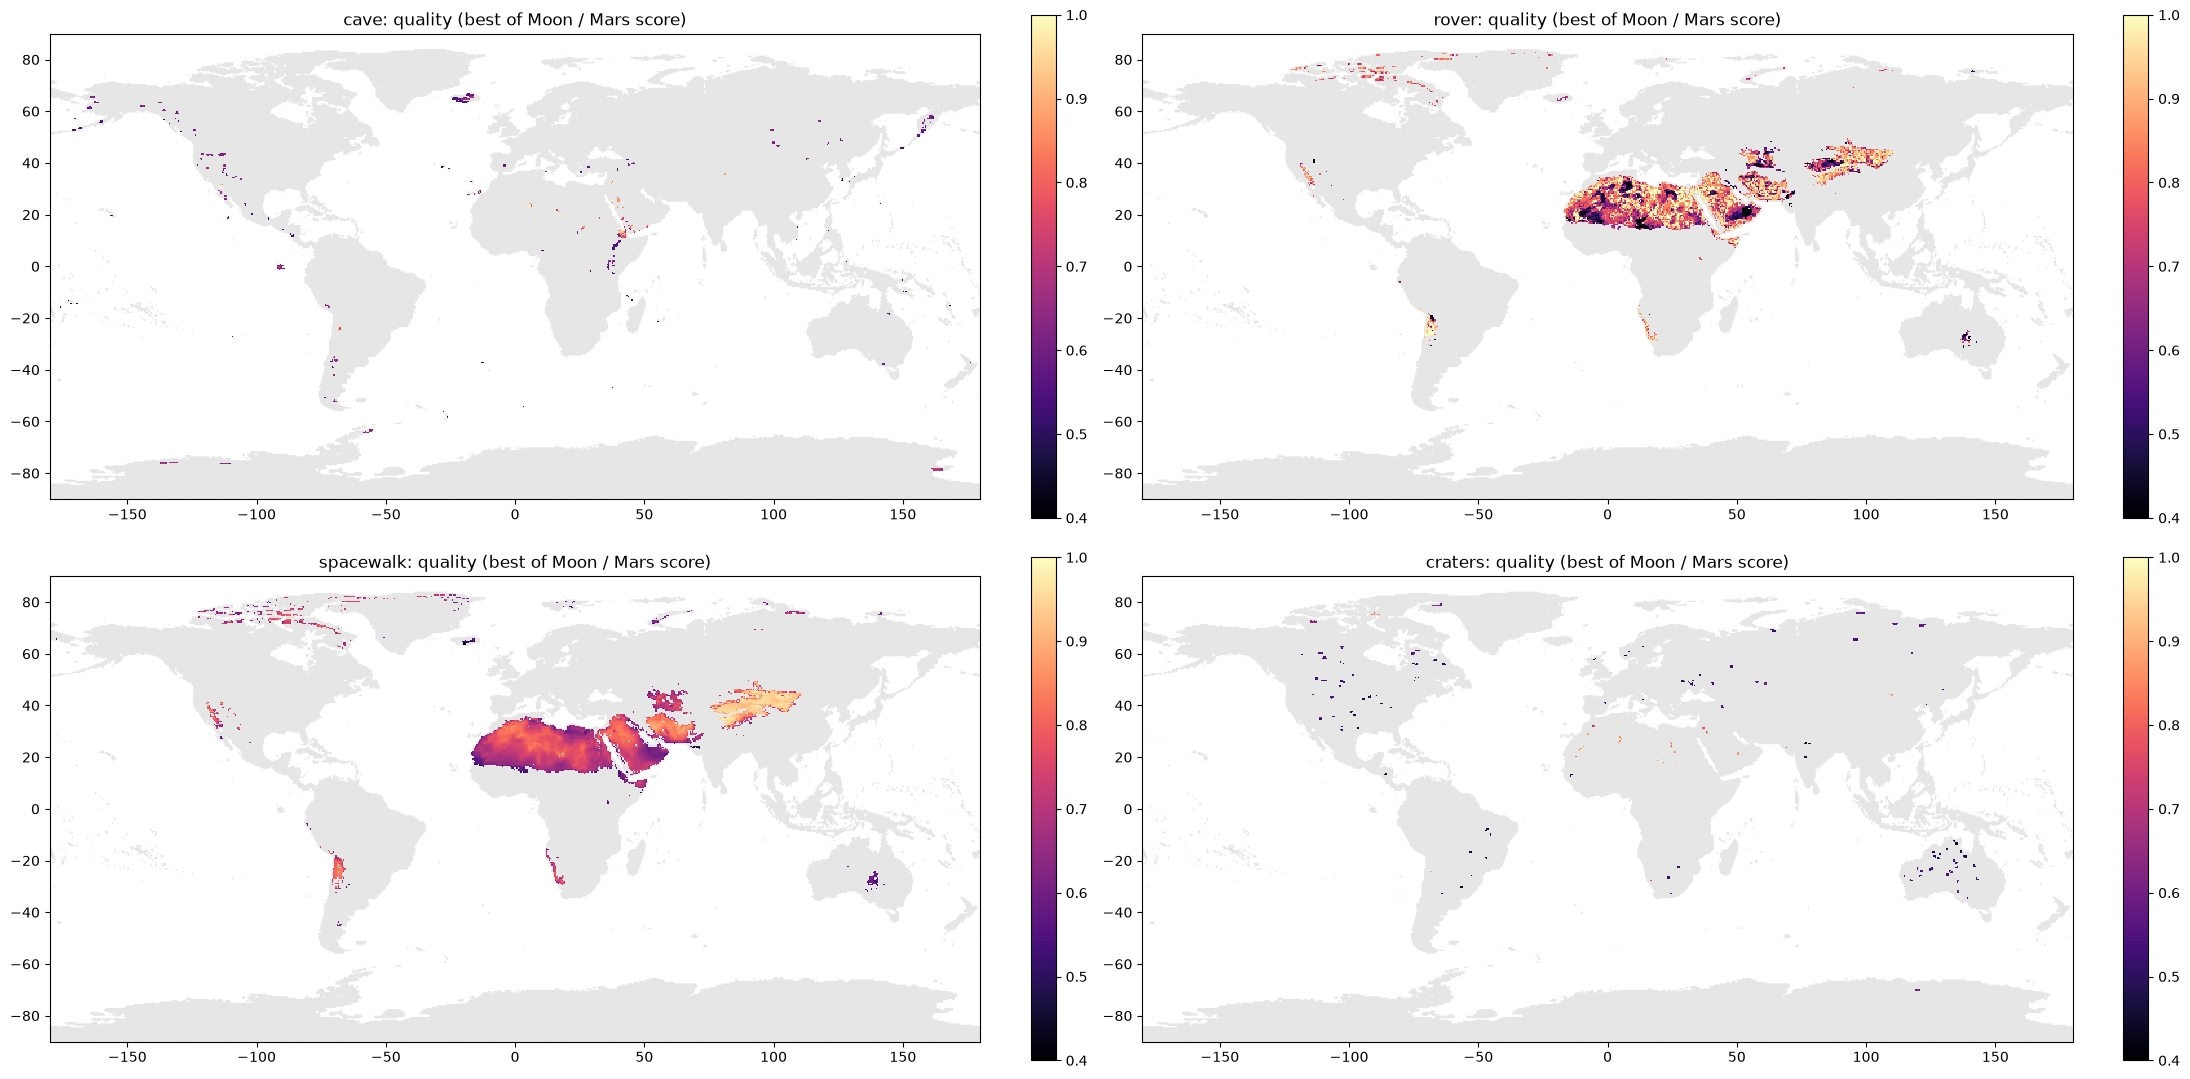

In [6]:
plots.label_maps(scored, apps, validation.application_sites()); plt.show()
plots.quality_maps(scored, apps); plt.show()